# Preparation

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
from itertools import combinations
from statsmodels.stats.multitest import multipletests

### Load analysis_dataset.csv

The raw file has **one row per participant** (96 rows, 102 columns). It is reshaped into a long table with **one row per review** (participant x round = 384 rows). The fields used by the rest of the notebook are

*   SID --> participant id (row number in the raw file, 1..96)
*   Group, Round --> crossover group (1-4) and review round (1-4)
*   Factors --> there are two factors, one per metric
    *   `SelectedPatchIsHuman` (Y / N) --> factor of Metric 1
    *   `LLMFor1stPatch` (G / C) --> factor of Metric 2
*   Scenario --> the vulnerability of the round: VUL4J-5, VUL4J-12, VUL4J-13, VUL4J-64
*   S1, S2 --> initial and final selection as stored in the raw file (0 / 1)
*   Swapped --> 1 if the comment starts with `(SWAPPED)` (groups 2 and 3)
*   DemoM1 --> Java experience (0-4)
*   DemoM2 --> Security experience (0-4)
*   IntervM1 --> **SwitchRate** item: 1 if the final selection S2 differs from the initial selection S1
*   SwitchTo --> direction of the switch: `none` (kept), `human` (switch in a N round, so towards the patch called human), `AI` (switch in a Y round, so towards the patch called LLM)
*   IntervM2 --> **FirstPatchRate** item: 1 if the initially selected patch is the one shown on the left (first)
*   SelectedLLM --> LLM of the initially selected patch (GPT-4o / Claude)
*   Delta --> rating gap: sum of the six ratings of the selected patch minus those of the other patch
*   AttentionOK --> 0 if an attention check of the round failed
*   Population --> academic (TUHH, VU, TN) or professional (companies)
*   Lines, Dispersion, Readability, Comments --> the four closing questions (perceived influence, 0-4)

After the long table, the notebook also builds a table with **one row per reviewer** (`pp`, 96 rows). It only contains counts (no averages): `SwitchToHuman` and `SwitchToAI` (0-2), `ClaudePicks` and `LeftPicks` (0-4) and the two profiles `Profile1` and `Profile2`.

In [2]:
# default: the dataset in the same folder as the notebook. If it is not there, choose it with a dialog
csv_file = "analysis_dataset.csv"

if not os.path.exists(csv_file):
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    csv_file = filedialog.askopenfilename(
        title="Select analysis_dataset.csv",
        filetypes=[("CSV files", "*.csv")]
    )

### Read data from .csv

From wide to long format. The factor levels come from the crossover design table (Group x Round).
The selections `RkS1`, `RkS2` are 0 = patch P1, 1 = patch P2, where P1/P2 follow the display order of groups 1 and 4.
Groups 2 and 3 saw the patches in the opposite order and all their comments start with `(SWAPPED)`, so for them 1 = left patch.

In [3]:
raw = pd.read_csv(csv_file)
raw["SID"] = np.arange(1, len(raw) + 1)

# crossover design: <LLMFor1stPatch, SelectedPatchIsHuman> for each group and round
DESIGN = {1: ["GY", "CN", "CN", "GY"], 2: ["CY", "GN", "GN", "CY"],
          3: ["CN", "GY", "GY", "CN"], 4: ["GN", "CY", "CY", "GN"]}
VUL = {1: "VUL4J-5", 2: "VUL4J-12", 3: "VUL4J-13", 4: "VUL4J-64"}
ITEMS = ["intention overall", "intention behavior", "intention security",
         "successful functionality", "successful security", "successful overall"]

rows, mismatches = [], 0
for _, x in raw.iterrows():
    g = int(x["Group ID"])
    for r in range(1, 5):
        llm_first, label = DESIGN[g][r - 1]
        swapped = str(x[f"R{r}S1 comment"]).startswith("(SWAPPED)")
        s1, s2 = int(x[f"R{r}S1"]), int(x[f"R{r}S2"])
        left = 1 if swapped else 0   # raw index of the patch shown on the left
        llm = {left: "GPT-4o" if llm_first == "G" else "Claude",
               1 - left: "Claude" if llm_first == "G" else "GPT-4o"}
        score = {c: sum(x[f"R{r}P{c + 1} {i}"] for i in ITEMS) for c in (0, 1)}
        att = [x[f"R{r}P{c} attention check"] for c in (1, 2)]
        # sanity checks against the columns already present in the dataset
        mismatches += int(x[f"R{r} chosen is human"]) != (label == "Y")
        mismatches += int(x[f"R{r} switch"]) != (s1 != s2)
        rows.append({
            "SID": x["SID"], "Group": g, "Round": r, "Scenario": VUL[r],
            "LLMFor1stPatch": llm_first, "SelectedPatchIsHuman": label,
            "S1": s1, "S2": s2, "Swapped": int(swapped),
            "IntervM1": int(s1 != s2),     # Metric 1: switch after the disclosure
            # direction of the switch: in N the other patch is the "human" one, in Y it is the "LLM" one
            "SwitchTo": "none" if s1 == s2 else ("human" if label == "N" else "AI"),
            "IntervM2": int(s1 == left),   # Metric 2: first (left) patch selected
            "SelectedLLM": llm[s1], "ClaudeSelected": int(llm[s1] == "Claude"),
            "Delta": score[s1] - score[1 - s1],                  # rating gap selected - other
            "AttentionOK": int(all(pd.isna(a) or a == 1 for a in att)),
            "Population": "professional" if x["Institute"] == "companies" else "academic",
            "DemoM1": x["Java experience"], "DemoM2": x["Security experience"]})
long = pd.DataFrame(rows)

# one row per participant: demographics and perception
data = pd.DataFrame({
    "SID": raw["SID"], "Group": raw["Group ID"].astype(int), "Institute": raw["Institute"],
    "Population": np.where(raw["Institute"] == "companies", "professional", "academic"),
    "DemoM1": raw["Java experience"], "DemoM2": raw["Security experience"],
    "Lines": raw["Impact number of lines"], "Dispersion": raw["Impact degree of dispersion"],
    "Readability": raw["Impact readability"], "Comments": raw["Impact comments"]})

print("participants:", len(data), " reviews:", len(long), " mismatches with dataset columns:", mismatches)
print("share of (SWAPPED) reviews per group:", long.groupby("Group").Swapped.mean().to_dict())
print("group sizes:", data.Group.value_counts().sort_index().to_dict())
long.head(8)

participants: 96  reviews: 384  mismatches with dataset columns: 0
share of (SWAPPED) reviews per group: {1: 0.0, 2: 1.0, 3: 1.0, 4: 0.0}
group sizes: {1: 24, 2: 27, 3: 22, 4: 23}


,SID,Group,Round,Scenario,LLMFor1stPatch,SelectedPatchIsHuman,S1,S2,Swapped,IntervM1,SwitchTo,IntervM2,SelectedLLM,ClaudeSelected,Delta,AttentionOK,Population,DemoM1,DemoM2
0,1,2,1,VUL4J-5,C,Y,0,0,1,0,none,0,GPT-4o,0,0,0,professional,4,4
1,1,2,2,VUL4J-12,G,N,0,0,1,0,none,0,Claude,1,8,1,professional,4,4
2,1,2,3,VUL4J-13,G,N,0,0,1,0,none,0,Claude,1,0,1,professional,4,4
3,1,2,4,VUL4J-64,C,Y,1,1,1,0,none,1,Claude,1,0,1,professional,4,4
4,2,1,1,VUL4J-5,G,Y,1,1,0,0,none,0,Claude,1,10,1,professional,4,4
5,2,1,2,VUL4J-12,C,N,1,1,0,0,none,0,GPT-4o,0,0,1,professional,4,4
6,2,1,3,VUL4J-13,C,N,0,0,0,0,none,1,Claude,1,0,1,professional,4,4
7,2,1,4,VUL4J-64,G,Y,0,0,0,0,none,1,GPT-4o,0,0,1,professional,4,4


In [4]:
MIN_DEMO1 = 0
MAX_DEMO1 = 4
MIN_DEMO2 = 0
MAX_DEMO2 = 4

In [5]:
MIN_PERC = 0
MAX_PERC = 4
PERC_ITEMS = ["Lines", "Dispersion", "Readability", "Comments"]

In [6]:
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9890"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dd"
# the first level of each factor is blue, the second orange (GPT-4o = blue, Claude = orange)
TREATMENT_COLORS = {"Y": BLUE, "N": ORANGE, "G": BLUE, "C": ORANGE,
                    "academic": BLUE, "professional": ORANGE, "all": BLUE}

plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "axes.titlesize": 10, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
                     "grid.color": GRID, "grid.linewidth": 0.6,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})

# figures are exported in the images folder next to the notebook
FIG_DIR = "images"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name))

In [7]:
SCENARIOS = ["VUL4J-5", "VUL4J-12", "VUL4J-13", "VUL4J-64"]   # fixed round order
SHORT = {"VUL4J-5": "V5", "VUL4J-12": "V12", "VUL4J-13": "V13", "VUL4J-64": "V64"}

# Demographic Analysis

## Histograms
Distributions of the self-reported experience, split by population (academic vs professional)

In [8]:
def produce_histogram(ax, data, treatment, treatmentVals, field, min, max, colors):
  values = np.arange(min, max + 1)
  if treatment is None:
    groups = [(None, data, colors["all"])]
  else:
    groups = [(v, data[data[treatment] == v], colors[v]) for v in treatmentVals]
  width = 0.8 / len(groups)
  for k, (v, d, c) in enumerate(groups):
    counts = d[field].value_counts().reindex(values, fill_value=0)
    pos = values + (k - (len(groups) - 1) / 2) * width
    bars = ax.bar(pos, counts.values, width=width - 0.04, color=c, label=v)
    ax.bar_label(bars, fontsize=8, color=INK)
  ax.set_xticks(values)
  ax.set_title(field)
  ax.set_xlim([min - 0.6, max + 0.6])
  return ax

### Demographic Histogram

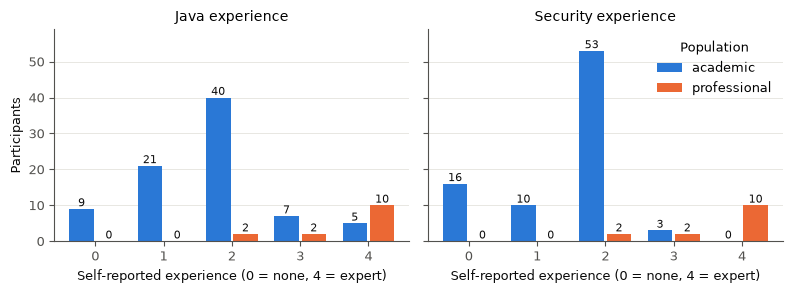

In [9]:
max_ylim = max(data.groupby(["DemoM1"])["SID"].count().max(), data.groupby(["DemoM2"])["SID"].count().max()) + 4

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3), sharey=True)

ax1 = produce_histogram(ax1, data, "Population", ["academic", "professional"], "DemoM1", MIN_DEMO1, MAX_DEMO1, TREATMENT_COLORS)
ax1.set_ylim([0, max_ylim])
ax1.set_title("Java experience")
ax1.set_ylabel("Participants")

ax2 = produce_histogram(ax2, data, "Population", ["academic", "professional"], "DemoM2", MIN_DEMO2, MAX_DEMO2, TREATMENT_COLORS)
ax2.set_ylim([0, max_ylim])
ax2.set_title("Security experience")
ax2.legend(frameon=False, title="Population")

for ax in (ax1, ax2):
  ax.set_xlabel("Self-reported experience\n(0 = none, 4 = professional practice)")

fig.tight_layout()
save(fig, "demo_hist.png")
plt.show()

## Scatter plots
Represent values for two different numeric variables to compare the two variables.

In [10]:
def scatter_plot(ax, data, treatment, treatmentVal, colors, first, second):
  data_scatter = data[data[treatment] == treatmentVal]
  color = colors[treatmentVal]

  a, ca = np.unique(np.c_[data_scatter[first], data_scatter[second]], return_counts=True, axis=0)
  ax.scatter(a[:, 0], a[:, 1], s=ca * 45 + 40, c=color, alpha=0.9, edgecolor="white", linewidth=1.5, zorder=3)
  for (x, y), n in zip(a, ca):
    ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=7, zorder=4)

  min1, max1 = MIN_DEMO1, MAX_DEMO1
  min2, max2 = MIN_DEMO2, MAX_DEMO2

  ax.set_xticks(np.arange(min1, max1 + 1, 1))
  ax.set_yticks(np.arange(min2, max2 + 1, 1))
  ax.set_xlim(min1 - 0.6, max1 + 0.6)
  ax.set_ylim(min2 - 0.6, max2 + 0.6)
  ax.grid(True, axis="both")
  ax.set_title(f"{treatmentVal} (n = {len(data_scatter)})")
  return ax

### Demographic Scatter Plot

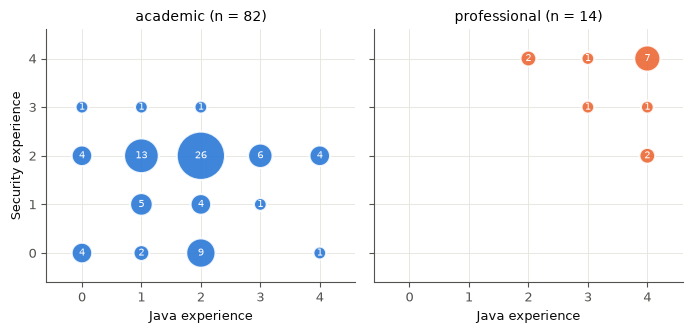

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4), sharey=True)

for ax, pop in zip(axes, ["academic", "professional"]):
  scatter_plot(ax, data, "Population", pop, TREATMENT_COLORS, "DemoM1", "DemoM2")
  ax.set_xlabel("Java experience")
axes[0].set_ylabel("Security experience")

fig.tight_layout()
save(fig, "demo_scatter.png")
plt.show()

# Intervention Metrics

## Per-reviewer view
The unit of the analysis is the **reviewer**, not the single review. Every reviewer has 2 rounds labelled Y and 2 labelled N, and 2 rounds with GPT-4o on the left (G) and 2 with Claude on the left (C). So for every reviewer only what they did is counted, no averages are computed:

*   `SwitchToHuman` = switches in the 2 N rounds (the reviewer leaves the patch called LLM and takes the one called human), 0-2
*   `SwitchToAI` = switches in the 2 Y rounds (the reviewer leaves the patch called human and takes the one called LLM), 0-2
*   `ClaudePicks` = initial choices that went to the Claude patch, 0-4
*   `LeftPicks` = initial choices that went to the left patch, 0-4

Every reviewer gets a profile for each metric, and the results are the **number of reviewers** in each profile.
A reviewer who chooses by content has to change side (Claude is on the left in 2 rounds and on the right in the other 2), while a reviewer who always takes the same side ends up with 2 Claude and 2 GPT-4o.

### Reviewer profiles

0   1   2  median
Metric 1 Y  85  10   1     0.0
         N  69  22   5     0.0
Metric 2 G  43  45   8     1.0
         C  20  34  42     1.0

Population,academic,professional,total
Profile1,,,
never switched,48,10,58
towards human,25,2,27
towards AI,9,2,11
both directions,0,0,0
total,82,14,96


Population,academic,professional,total
Profile2,,,
mostly Claude,42,10,52
mostly GPT-4o,11,1,12
"2-2, changing side",16,2,18
"2-2, always same side",13,1,14
total,82,14,96


switches towards human x switches towards AI (number of reviewers):


SwitchToAI,0,1,2
SwitchToHuman,,,
0,58,10,1
1,22,0,0
2,5,0,0


Claude picks (0-4), number of reviewers: {0: 2, 1: 10, 2: 32, 3: 33, 4: 19}
2-2 reviewers by left picks: {0: 10, 2: 18, 4: 4}


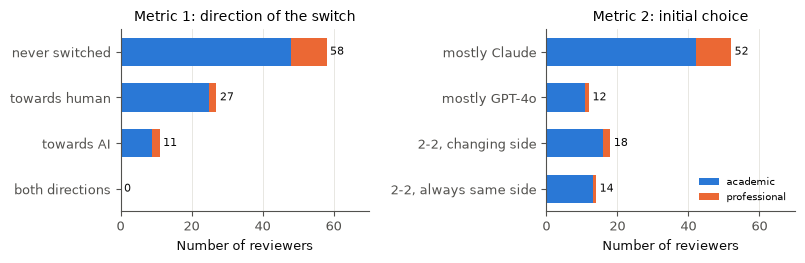

In [12]:
# one row per reviewer, only counts
pp = (long.assign(ToHuman=(long.SwitchTo == "human").astype(int), ToAI=(long.SwitchTo == "AI").astype(int))
          .groupby("SID")
          .agg(SwitchToHuman=("ToHuman", "sum"), SwitchToAI=("ToAI", "sum"),
               ClaudePicks=("ClaudeSelected", "sum"), LeftPicks=("IntervM2", "sum"),
               Population=("Population", "first")))

PROFILE1 = ["never switched", "towards human", "towards AI", "both directions"]
PROFILE2 = ["mostly Claude", "mostly GPT-4o", "2-2, changing side", "2-2, always same side"]
pp["Profile1"] = np.select([(pp.SwitchToHuman == 0) & (pp.SwitchToAI == 0), pp.SwitchToAI == 0, pp.SwitchToHuman == 0],
                           PROFILE1[:3], PROFILE1[3])
pp["Profile2"] = np.select([pp.ClaudePicks >= 3, pp.ClaudePicks <= 1, pp.LeftPicks.isin([0, 4])],
                           ["mostly Claude", "mostly GPT-4o", "2-2, always same side"], "2-2, changing side")

def profile_table(col, order):
  t = pd.crosstab(pp[col], pp.Population, margins=True, margins_name="total").reindex(order + ["total"], fill_value=0)
  return t

# distribution of the counts at each factor level (Table "Distribution of the metrics among the factor levels")
def level_counts(metric, factor, levels):
  w = long.pivot_table(index="SID", columns=factor, values=metric, aggfunc="sum")
  t = pd.DataFrame({lev: w[lev].value_counts().reindex([0, 1, 2], fill_value=0) for lev in levels}).T
  t["median"] = [w[lev].median() for lev in levels]
  return t

display(pd.concat([level_counts("IntervM1", "SelectedPatchIsHuman", ["Y", "N"]),
                   level_counts("IntervM2", "LLMFor1stPatch", ["G", "C"])], keys=["Metric 1", "Metric 2"]))
display(profile_table("Profile1", PROFILE1))
display(profile_table("Profile2", PROFILE2))
print("switches towards human x switches towards AI (number of reviewers):")
display(pd.crosstab(pp.SwitchToHuman, pp.SwitchToAI))
print("Claude picks (0-4), number of reviewers:", pp.ClaudePicks.value_counts().sort_index().to_dict())
print("2-2 reviewers by left picks:", pp[pp.ClaudePicks == 2].LeftPicks.value_counts().sort_index().to_dict())

def profile_bars(ax, col, order, title):
  # horizontal stacked bars: number of reviewers in each profile, academics + professionals
  y = np.arange(len(order))[::-1]
  left = np.zeros(len(order))
  for pop in ["academic", "professional"]:
    n = pp[pp.Population == pop][col].value_counts().reindex(order, fill_value=0).values
    ax.barh(y, n, left=left, height=0.62, color=TREATMENT_COLORS[pop], label=pop)
    left += n
  for yi, tot in zip(y, left):
    ax.text(tot + 1, yi, f"{int(tot)}", va="center", fontsize=8, color=INK)
  ax.set_yticks(y, order)
  ax.set_xlim(0, 70)
  ax.set_xlabel("Number of reviewers")
  ax.grid(True, axis="x")
  ax.grid(False, axis="y")
  ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 2.7))
profile_bars(axes[0], "Profile1", PROFILE1, "Metric 1: direction of the switch")
profile_bars(axes[1], "Profile2", PROFILE2, "Metric 2: initial choice")
axes[1].legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout()
save(fig, "interv_profiles.png")
plt.show()

### Intervention plot by Scenario

sum  count   rate
         Scenario                     
Metric 1 VUL4J-12 N   11     51  0.216
                  Y    2     45  0.044
         VUL4J-13 N   10     51  0.196
                  Y    1     45  0.022
         VUL4J-5  N    8     45  0.178
                  Y    5     51  0.098
         VUL4J-64 N    3     45  0.067
                  Y    4     51  0.078
Metric 2 VUL4J-12 C   31     47  0.660
                  G   23     49  0.469
         VUL4J-13 C   32     47  0.681
                  G   14     49  0.286
         VUL4J-5  C   28     49  0.571
                  G   12     47  0.255
         VUL4J-64 C   27     49  0.551
                  G   12     47  0.255

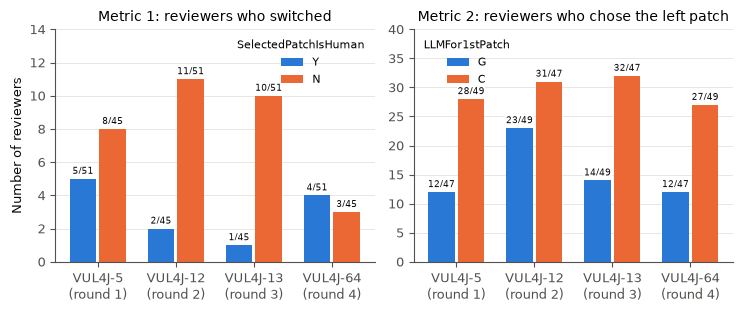

In [13]:
# every reviewer sees each vulnerability once, so here the counts are numbers of reviewers
def by_scenario(metric, factor):
  t = long.groupby(["Scenario", factor])[metric].agg(["sum", "count"])
  t["rate"] = t["sum"] / t["count"]
  return t

S1 = by_scenario("IntervM1", "SelectedPatchIsHuman")
S2 = by_scenario("IntervM2", "LLMFor1stPatch")
display(pd.concat([S1, S2], keys=["Metric 1", "Metric 2"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
x = np.arange(len(SCENARIOS))
w = 0.38
for ax, S, levels, ymax, title in [(axes[0], S1, ["Y", "N"], 14, "Metric 1: reviewers who switched"),
                                   (axes[1], S2, ["G", "C"], 40, "Metric 2: reviewers who chose the left patch")]:
  for j, lev in enumerate(levels):
    cnt = [S.loc[(v, lev), "sum"] for v in SCENARIOS]
    k = [f"{S.loc[(v, lev), 'sum']}/{S.loc[(v, lev), 'count']}" for v in SCENARIOS]
    bars = ax.bar(x + (j - 0.5) * w, cnt, w - 0.04, color=TREATMENT_COLORS[lev], label=lev)
    ax.bar_label(bars, labels=k, fontsize=6.5, color=INK, padding=2, bbox=dict(fc="white", ec="none", pad=0.5))
  ax.set_xticks(x, [f"{v}\n(round {i + 1})" for i, v in enumerate(SCENARIOS)])
  ax.set_ylim(0, ymax)
  ax.set_title(title)
axes[0].legend(title="SelectedPatchIsHuman", frameon=False, fontsize=8, title_fontsize=8)
axes[1].legend(title="LLMFor1stPatch", frameon=False, fontsize=8, title_fontsize=8, loc="upper left")
axes[0].set_ylabel("Number of reviewers")
fig.tight_layout()
save(fig, "interv_by_scenario.png")
plt.show()

## Scatter plot
Paired view: every bubble is a group of reviewers with the same pair of counts (bubble label = number of reviewers). Points above the diagonal (orange) mean more events at the second level of the factor (N or C), points below (blue) more events at the first level (Y or G), gray points are on the diagonal (no difference).

### Intervention Scatter Plot by treatment (per participant)

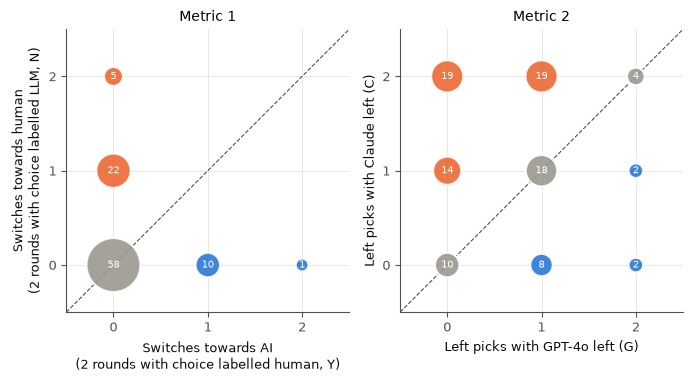

In [14]:
pp1 = long.pivot_table(index="SID", columns="SelectedPatchIsHuman", values="IntervM1", aggfunc="sum")
pp2 = long.pivot_table(index="SID", columns="LLMFor1stPatch", values="IntervM2", aggfunc="sum")

def paired_bubbles(ax, xs, ys, colors):
  # colors = (below diagonal, on diagonal, above diagonal)
  a, ca = np.unique(np.c_[xs, ys], return_counts=True, axis=0)
  ax.plot([-0.5, 2.5], [-0.5, 2.5], color=MUTED, lw=0.8, ls="--", zorder=1)
  c = [colors[int(np.sign(y - x)) + 1] for x, y in a]
  ax.scatter(a[:, 0], a[:, 1], s=ca * 25 + 60, c=c, alpha=0.9, edgecolor="white", linewidth=1.5, zorder=3)
  for (x, y), n in zip(a, ca):
    ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=7, zorder=4)
  ticks = [0, 1, 2]
  ax.set_xticks(ticks)
  ax.set_yticks(ticks)
  ax.set_xlim(-0.5, 2.5)
  ax.set_ylim(-0.5, 2.5)
  ax.grid(True, axis="both")
  ax.set_aspect("equal")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.6))
paired_bubbles(ax1, pp1["Y"], pp1["N"], (BLUE, GRAY, ORANGE))
ax1.set_xlabel("Switches towards AI\n(2 rounds with choice labelled human, Y)")
ax1.set_ylabel("Switches towards human\n(2 rounds with choice labelled LLM, N)")
ax1.set_title("Metric 1")
paired_bubbles(ax2, pp2["G"], pp2["C"], (BLUE, GRAY, ORANGE))
ax2.set_xlabel("Left picks with GPT-4o left (G)")
ax2.set_ylabel("Left picks with Claude left (C)")
ax2.set_title("Metric 2")
fig.tight_layout()
save(fig, "interv_scatter.png")
plt.show()

# Perception Metric

## Histograms
The perception questions are asked once, at the end of the questionnaire, so there is one value per participant and per item.

### Perception Histogram

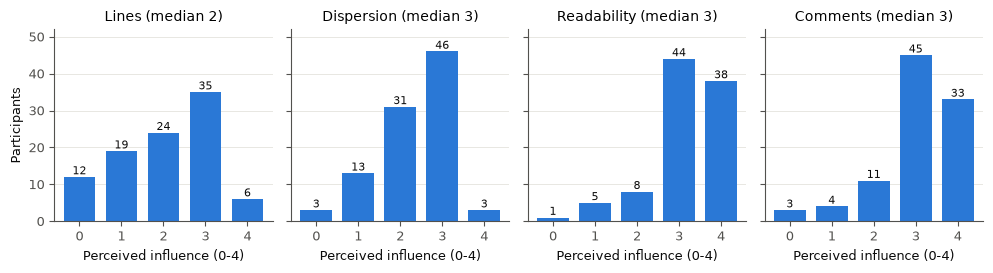

        Lines  Dispersion  Readability  Comments
mean     2.04        2.34         3.18      3.05
median   2.00        3.00         3.00      3.00
std      1.15        0.87         0.87      0.96
share of participants with rating >= 3:
 Lines          0.43
Dispersion     0.51
Readability    0.85
Comments       0.81
dtype: float64


In [15]:
max_ylim = max(data[c].value_counts().max() for c in PERC_ITEMS) + 6

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), sharey=True)
for ax, c in zip(axes, PERC_ITEMS):
  produce_histogram(ax, data, None, None, c, MIN_PERC, MAX_PERC, TREATMENT_COLORS)
  ax.set_ylim([0, max_ylim])
  ax.set_title(f"{c} (median {data[c].median():g})")
  ax.set_xlabel("Perceived influence (0-4)")
axes[0].set_ylabel("Participants")
fig.tight_layout()
save(fig, "perc_hist.png")
plt.show()

print(data[PERC_ITEMS].agg(["mean", "median", "std"]).round(2))
print("share of participants with rating >= 3:\n", (data[PERC_ITEMS] >= 3).mean().round(2))

## Boxplots

### Perception Boxplot by switching profile (Metric 1)
Perception is not measured per round, so it cannot be split by the level of a factor. For Metric 1 the reviewers are split by their profile: never switched, switched only towards the "human" patch, switched only towards the "LLM" patch (nobody switched in both directions).

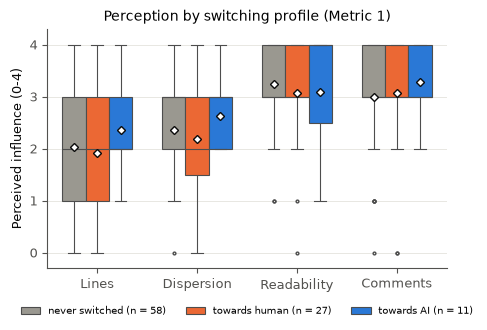

In [16]:
data = data.drop(columns=["SwitchToHuman", "SwitchToAI", "ClaudePicks", "LeftPicks", "Profile1", "Profile2", "Preference"],
                 errors="ignore").merge(pp.drop(columns="Population"), left_on="SID", right_index=True)
data["Preference"] = np.select([data.ClaudePicks >= 3, data.ClaudePicks <= 1], ["mostly Claude", "mostly GPT-4o"], "tie (2-2)")

perc_long = data.melt(id_vars=["SID", "Profile1", "Preference"], value_vars=PERC_ITEMS, var_name="Item", value_name="Influence")

def perc_box(ax, hue, order, palette):
  sns.boxplot(data=perc_long, x="Item", y="Influence", hue=hue, hue_order=order, palette=palette, ax=ax,
              width=0.7, linewidth=0.8, fliersize=2, showmeans=True, saturation=1,
              meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=INK, markersize=4))
  ax.set_xlabel("")
  ax.set_ylabel("Perceived influence (0-4)")
  ax.set_ylim(-0.3, 4.3)
  counts = data[hue].value_counts()
  handles, labels = ax.get_legend_handles_labels()
  ax.legend(handles, [f"{l} (n = {counts[l]})" for l in labels], frameon=False, fontsize=7,
            loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(order))

fig, ax = plt.subplots(figsize=(5, 3.4))
perc_box(ax, "Profile1", ["never switched", "towards human", "towards AI"], [GRAY, ORANGE, BLUE])
ax.set_title("Perception by switching profile (Metric 1)")
fig.tight_layout()
save(fig, "perc_by_switch.png")
plt.show()

### Perception Boxplot by preferred LLM (Metric 2)
For Metric 2 the participants are split by the LLM they chose in the majority of their four initial selections (GPT-4o blue, Claude orange, 2-2 ties gray). The same perception cannot be split by vulnerability because it is asked only once.

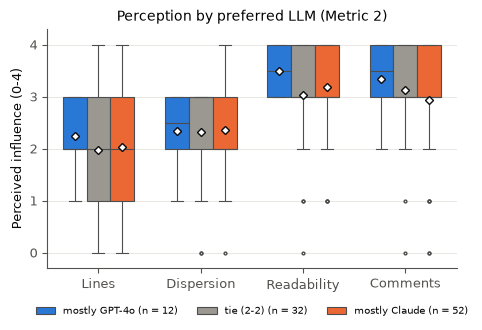

In [17]:
fig, ax = plt.subplots(figsize=(5, 3.4))
perc_box(ax, "Preference", ["mostly GPT-4o", "tie (2-2)", "mostly Claude"], [BLUE, GRAY, ORANGE])
ax.set_title("Perception by preferred LLM (Metric 2)")
fig.tight_layout()
save(fig, "perc_by_preference.png")
plt.show()

# Statistical Test

## Zero vs non-zero and paired Wilcoxon test

Both metrics are binary for a single review, so the "zero vs non-zero" split is natural and no threshold is needed:

1.   Metric 1: 0 = the participant kept the initial choice, 1 = switched
2.   Metric 2: 0 = the second (right) patch was selected, 1 = the first (left) patch was selected

The first cell gives the event frequencies, overall and per vulnerability (Table "Zero vs Non-Zero grouping"). No chi-square test is run on them: it would treat the 384 reviews as independent, which is not true (4 reviews per participant). The paired tests come right after.

In [18]:
# event frequencies over all reviews (zero / non-zero)
for factor, metric in [("SelectedPatchIsHuman", "IntervM1"), ("LLMFor1stPatch", "IntervM2")]:
  print(pd.crosstab(long[factor], long[metric]), "\n")

# event frequencies per vulnerability (zero / non-zero)
freq = pd.concat({
  "M1": long.pivot_table(index="Scenario", columns=["SelectedPatchIsHuman", "IntervM1"], values="SID", aggfunc="count"),
  "M2": long.pivot_table(index="Scenario", columns=["LLMFor1stPatch", "IntervM2"], values="SID", aggfunc="count")}, axis=1)
freq.loc[SCENARIOS]

IntervM1                0   1
SelectedPatchIsHuman         
N                     160  32
Y                     180  12 

IntervM2          0    1
LLMFor1stPatch          
C                74  118
G               131   61 



M1             M2            
           N       Y      C       G    
           0   1   0  1   0   1   0   1
Scenario                               
VUL4J-5   37   8  46  5  21  28  35  12
VUL4J-12  40  11  43  2  16  31  26  23
VUL4J-13  41  10  44  1  15  32  35  14
VUL4J-64  42   3  47  4  22  27  35  12

Paired Wilcoxon signed-rank test. The template uses the rank-sum test, which is for independent samples. Here the same participant is observed at both levels of each factor (two reviews per level), so the test is applied to the per-participant differences $d_p$ = (switches in N) - (switches in Y) and $e_p$ = (left picks in C) - (left picks in G), all counts out of 2. Zero differences are discarded (`zero_method="wilcox"`), which is the "non-zero part" of the data. The effect size is the matched-pairs rank-biserial correlation.

In [19]:
def wilcoxon_paired(metric, factor, a, b):
  w = long.pivot_table(index="SID", columns=factor, values=metric, aggfunc="sum")
  d = w[a] - w[b]
  nz = d[d != 0]
  res = stats.wilcoxon(w[a], w[b], zero_method="wilcox", correction=True, method="approx")
  ranks = stats.rankdata(nz.abs())
  w_pos, w_neg = ranks[nz.values > 0].sum(), ranks[nz.values < 0].sum()
  return {"W": res.statistic, "p": res.pvalue, "n_nonzero": len(nz), "n_pos": (nz > 0).sum(),
          "n_neg": (nz < 0).sum(), "n_zero": (d == 0).sum(), "r_rb": (w_pos - w_neg) / (w_pos + w_neg)}

W = pd.DataFrame({"Metric 1 (N vs Y)": wilcoxon_paired("IntervM1", "SelectedPatchIsHuman", "N", "Y"),
                  "Metric 2 (C vs G)": wilcoxon_paired("IntervM2", "LLMFor1stPatch", "C", "G")}).T
W["p Holm"] = multipletests(W.p.astype(float), method="holm")[1]
W

,W,p,n_nonzero,n_pos,n_neg,n_zero,r_rb,p Holm
Metric 1 (N vs Y),200.5,7.874268e-03,38.0,27.0,11.0,58.0,0.458839,0.007874
Metric 2 (C vs G),328.0,6.768961e-07,64.0,52.0,12.0,32.0,0.684615,0.000001


Sign test on the reviewer profiles. It only looks at the direction of every reviewer:
for Metric 1, among the reviewers who switched at least once, how many went towards human and how many towards AI; for Metric 2, how many reviewers mostly chose Claude and how many mostly GPT-4o.
The last test checks the 2-2 reviewers: if they picked at random, 2 of the 6 possible 2-2 patterns are "always the same side", so we expect 1/3 of them there.

In [20]:
sign = []
def sign_row(name, k, n, p0=0.5, alternative="two-sided"):
  t = stats.binomtest(k, n, p0, alternative=alternative)
  sign.append({"test": name, "k": k, "n": n, "p0": p0, "p": t.pvalue})

h, a = (pp.Profile1 == "towards human").sum(), (pp.Profile1 == "towards AI").sum()
sign_row("M1: towards human vs towards AI", h, h + a)
c, g = (pp.Profile2 == "mostly Claude").sum(), (pp.Profile2 == "mostly GPT-4o").sum()
sign_row("M2: mostly Claude vs mostly GPT-4o", c, c + g)
ties = pp[pp.ClaudePicks == 2]
sign_row("M2: 2-2 reviewers always on the same side", ties.LeftPicks.isin([0, 4]).sum(), len(ties), 1 / 3, "greater")
pd.DataFrame(sign).set_index("test").round(4)

,k,n,p0,p
test,,,,
M1: towards human vs towards AI,27,38,0.5000,0.0139
M2: mostly Claude vs mostly GPT-4o,52,64,0.5000,0.0000
M2: 2-2 reviewers always on the same side,14,32,0.3333,0.1444


## Control of the scenarios (vulnerabilities)

Two different questions:
1. Is the effect of the factor present **inside each vulnerability**? Fisher exact test per vulnerability (N vs Y for Metric 1, C vs G for Metric 2), Holm correction over the 4 vulnerabilities.
2. Do the vulnerabilities **differ from each other**? Pairwise Fisher tests between vulnerabilities on the number of reviewers who switched (Metric 1) and on the share of Claude choices (Metric 2, the quantity that the order factor reveals), Holm correction over the 6 pairs.

In [21]:
def fisher_by_scenario(metric, factor, hi, lo):
  out = []
  for v in SCENARIOS:
    g = long[long.Scenario == v]
    a = g[g[factor] == hi][metric]
    b = g[g[factor] == lo][metric]
    table = [[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]
    o, p = stats.fisher_exact(table)
    out.append({"Scenario": v, f"{hi}": f"{a.sum()}/{len(a)}", f"{lo}": f"{b.sum()}/{len(b)}", "OR": o, "p": p})
  out = pd.DataFrame(out).set_index("Scenario")
  out["p Holm"] = multipletests(out.p, method="holm")[1]
  return out

print("Metric 1, switch N vs Y within each vulnerability")
display(fisher_by_scenario("IntervM1", "SelectedPatchIsHuman", "N", "Y").round(4))
print("Metric 2, first patch chosen C vs G within each vulnerability")
display(fisher_by_scenario("IntervM2", "LLMFor1stPatch", "C", "G").round(4))
print("Claude share per vulnerability")
long.groupby("Scenario").ClaudeSelected.agg(["sum", "count", "mean"]).loc[SCENARIOS].round(3)

Metric 1, switch N vs Y within each vulnerability


,N,Y,OR,p,p Holm
Scenario,,,,,
VUL4J-5,8/45,5/51,1.9892,0.3712,0.7423
VUL4J-12,11/51,2/45,5.9125,0.0172,0.0515
VUL4J-13,10/51,1/45,10.7317,0.0090,0.0361
VUL4J-64,3/45,4/51,0.8393,1.0000,1.0000


Metric 2, first patch chosen C vs G within each vulnerability


,C,G,OR,p,p Holm
Scenario,,,,,
VUL4J-5,28/49,12/47,3.8889,0.0020,0.0061
VUL4J-12,31/47,23/49,2.1902,0.0678,0.0678
VUL4J-13,32/47,14/49,5.3333,0.0002,0.0008
VUL4J-64,27/49,12/47,3.5795,0.0038,0.0077


Claude share per vulnerability


,sum,count,mean
Scenario,,,
VUL4J-5,63,96,0.656
VUL4J-12,57,96,0.594
VUL4J-13,67,96,0.698
VUL4J-64,62,96,0.646


In [22]:
scenario_pairs = list(combinations(SCENARIOS, 2))

def pairwise_scenarios(col):
  out = []
  for s1, s2 in scenario_pairs:
    a, b = long[long.Scenario == s1][col], long[long.Scenario == s2][col]
    o, p = stats.fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    out.append({"pair": f"{s1} vs {s2}", "rate 1": a.mean(), "rate 2": b.mean(), "OR": o, "p": p})
  out = pd.DataFrame(out).set_index("pair")
  out["p Holm"] = multipletests(out.p, method="holm")[1]
  return out

print("Metric 1: switch rate (all reviews) between vulnerabilities")
display(pairwise_scenarios("IntervM1").round(4))
print("Metric 2: share of Claude choices between vulnerabilities")
pairwise_scenarios("ClaudeSelected").round(4)

Metric 1: switch rate (all reviews) between vulnerabilities


,rate 1,rate 2,OR,p,p Holm
pair,,,,,
VUL4J-5 vs VUL4J-12,0.1354,0.1354,1.0000,1.0000,1.0
VUL4J-5 vs VUL4J-13,0.1354,0.1146,1.2103,0.8277,1.0
VUL4J-5 vs VUL4J-64,0.1354,0.0729,1.9914,0.2370,1.0
VUL4J-12 vs VUL4J-13,0.1354,0.1146,1.2103,0.8277,1.0
VUL4J-12 vs VUL4J-64,0.1354,0.0729,1.9914,0.2370,1.0
VUL4J-13 vs VUL4J-64,0.1146,0.0729,1.6454,0.4585,1.0


Metric 2: share of Claude choices between vulnerabilities


,rate 1,rate 2,OR,p,p Holm
pair,,,,,
VUL4J-5 vs VUL4J-12,0.6562,0.5938,1.3062,0.4562,1.0
VUL4J-5 vs VUL4J-13,0.6562,0.6979,0.8263,0.6435,1.0
VUL4J-5 vs VUL4J-64,0.6562,0.6458,1.0469,1.0000,1.0
VUL4J-12 vs VUL4J-13,0.5938,0.6979,0.6326,0.1742,1.0
VUL4J-12 vs VUL4J-64,0.5938,0.6458,0.8015,0.5522,1.0
VUL4J-13 vs VUL4J-64,0.6979,0.6458,1.2670,0.5389,1.0


# [OPTIONAL] Additional analysis
Model-based confirmation of the paired tests (logistic GEE), descriptive numbers used in the report and the extra figures (causal diagram, rating gap vs switch).

In [23]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

long["N"] = (long.SelectedPatchIsHuman == "N").astype(int)
long["ClaudeFirst"] = (long.LLMFor1stPatch == "C").astype(int)

def gee(formula, d):
  # logistic GEE, exchangeable correlation between the 4 reviews of a participant
  return smf.gee(formula, groups="SID", data=d, family=sm.families.Binomial(),
                 cov_struct=sm.cov_struct.Exchangeable()).fit()

def or_row(m, term):
  return {"OR": np.exp(m.params[term]), "p": m.pvalues[term]}

## GEE models for Metric 1 (SwitchRate)

In [24]:
m1 = gee("IntervM1 ~ N + C(Round)", long)
display(pd.DataFrame({"label N vs Y": or_row(m1, "N")}).T.round(4))
print("failed attention checks (reviews):", (long.AttentionOK == 0).sum())
print("professionals, switches per level:",
      long[long.Population == "professional"].groupby("SelectedPatchIsHuman").IntervM1.agg(["sum", "count"]).to_dict("index"))
print("switches per participant (0, 1, 2 ...):", long.groupby("SID").IntervM1.sum().value_counts().sort_index().to_dict())

,OR,p
label N vs Y,2.9984,0.0072


failed attention checks (reviews): 47
professionals, switches per level: {'N': {'sum': 2, 'count': 28}, 'Y': {'sum': 2, 'count': 28}}
switches per participant (0, 1, 2 ...): {0: 58, 1: 32, 2: 6}


## GEE models for Metric 2 (FirstPatchRate)

In [25]:
m2 = gee("IntervM2 ~ ClaudeFirst + C(Round)", long)
display(pd.DataFrame({"Claude first vs GPT first": or_row(m2, "ClaudeFirst")}).T.round(4))

print("rating gap of the selected patch (reviews): higher", (long.Delta > 0).sum(), " equal", (long.Delta == 0).sum(),
      " lower", (long.Delta < 0).sum())
print("switches with Delta <= 0, by direction:", long[long.Delta <= 0].SwitchTo.value_counts().to_dict())

,OR,p
Claude first vs GPT first,3.5496,0.0


rating gap of the selected patch (reviews): higher 224  equal 117  lower 43
switches with Delta <= 0, by direction: {'none': 135, 'human': 18, 'AI': 7}


## Descriptive statistics of the participants

In [26]:
print("institute:", data.Institute.value_counts().to_dict())
print(data.groupby("Population")[["DemoM1", "DemoM2"]].agg(["count", "mean", "median"]).round(2))
print(data[["DemoM1", "DemoM2"]].agg(["mean", "median", "std"]).round(2))
print("Java 0-4:", data.DemoM1.value_counts().reindex(range(5), fill_value=0).to_dict())
print("Security 0-4:", data.DemoM2.value_counts().reindex(range(5), fill_value=0).to_dict())
print("both <= 1:", ((data.DemoM1 <= 1) & (data.DemoM2 <= 1)).sum(),
      " both >= 3:", ((data.DemoM1 >= 3) & (data.DemoM2 >= 3)).sum(),
      " of which professionals:", ((data.DemoM1 >= 3) & (data.DemoM2 >= 3) & (data.Population == "professional")).sum())
print("most frequent (Java, Security) cells:")
print(data.groupby(["DemoM1", "DemoM2"]).size().sort_values(ascending=False).head(4))

institute: {'tuhh': 59, 'companies': 14, 'vu': 13, 'tn': 10}
             DemoM1              DemoM2             
              count  mean median  count  mean median
Population                                          
academic         82  1.73    2.0     82  1.52    2.0
professional     14  3.57    4.0     14  3.57    4.0
        DemoM1  DemoM2
mean      2.00    1.82
median    2.00    2.00
std       1.15    1.10
Java 0-4: {0: 9, 1: 21, 2: 42, 3: 9, 4: 15}
Security 0-4: {0: 16, 1: 10, 2: 55, 3: 5, 4: 10}
both <= 1: 11  both >= 3: 10  of which professionals: 10
most frequent (Java, Security) cells:
DemoM1  DemoM2
2       2         26
1       2         13
2       0          9
4       4          7
dtype: int64


## Rating gap of the initial choice vs switch (appendix figure)

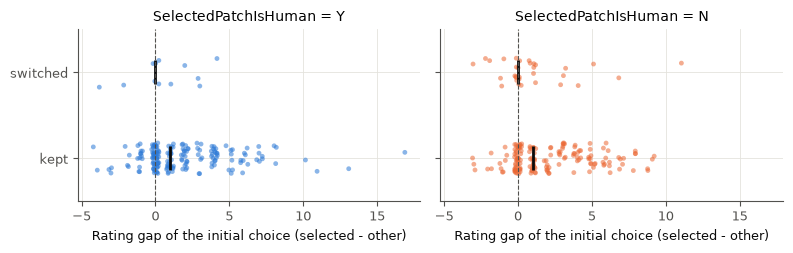

                               count  median  min  max
SelectedPatchIsHuman IntervM1                         
N                    0           160     1.0   -3    9
                     1            32     0.0   -3   11
Y                    0           180     1.0   -4   17
                     1            12     0.0   -4    4


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True, sharex=True)
rng = np.random.default_rng(3)
for ax, lev in zip(axes, ["Y", "N"]):
  d = long[long.SelectedPatchIsHuman == lev]
  for k in [0, 1]:
    v = d[d.IntervM1 == k].Delta
    ax.scatter(v + rng.uniform(-0.25, 0.25, len(v)), k + rng.uniform(-0.18, 0.18, len(v)),
               s=12, color=TREATMENT_COLORS[lev], alpha=0.55, edgecolor="none")
    ax.scatter(v.median(), k, marker="|", s=300, color=INK, lw=2)
  ax.axvline(0, color=MUTED, lw=0.8, ls="--")
  ax.set_yticks([0, 1], ["kept", "switched"])
  ax.set_ylim(-0.5, 1.5)
  ax.set_xlabel("Rating gap of the initial choice (selected - other)")
  ax.set_title(f"SelectedPatchIsHuman = {lev}")
  ax.grid(True, axis="x")
fig.tight_layout()
save(fig, "gap_vs_switch.png")
plt.show()

print(long.groupby(["SelectedPatchIsHuman", "IntervM1"]).Delta.agg(["count", "median", "min", "max"]))

## Causal diagram of the two metrics
Blue boxes are the randomized factors, orange boxes the outcomes, dashed boxes are latent or not manipulated variables. The dashed arrow is the only non-randomized path (vulnerability / patch pair).

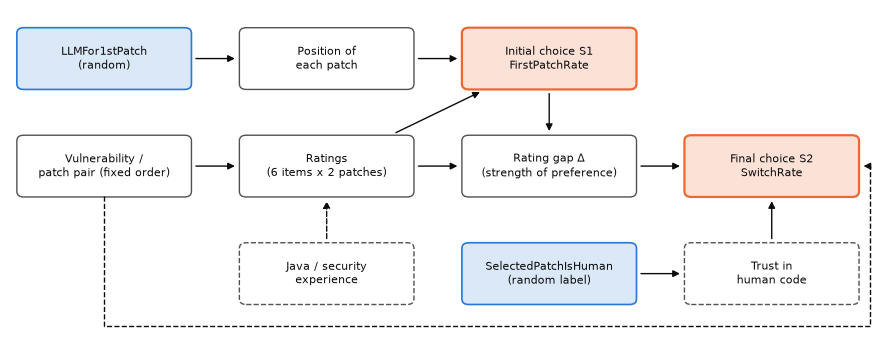

In [28]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.set_xlim(0, 10.2)
ax.set_ylim(-0.2, 4.6)
ax.axis("off")

BW, BH = 2.0, 0.85
STYLE = {"factor": dict(fc="#dbe8f8", ec=BLUE, ls="-", lw=1.2),
         "outcome": dict(fc="#fbe1d6", ec=ORANGE, ls="-", lw=1.6),
         "var": dict(fc="white", ec=MUTED, ls="-", lw=1.0),
         "latent": dict(fc="white", ec=MUTED, ls="--", lw=1.0)}
NODES = {
  "order": (1.1, 3.9, "LLMFor1stPatch\n(random)", "factor"),
  "pos":   (3.7, 3.9, "Position of\neach patch", "var"),
  "s1":    (6.3, 3.9, "Initial choice S1\nFirstPatchRate", "outcome"),
  "pair":  (1.1, 2.35, "Vulnerability /\npatch pair (fixed order)", "var"),
  "rat":   (3.7, 2.35, "Ratings\n(6 items x 2 patches)", "var"),
  "gap":   (6.3, 2.35, "Rating gap $\\Delta$\n(strength of preference)", "var"),
  "s2":    (8.9, 2.35, "Final choice S2\nSwitchRate", "outcome"),
  "exp":   (3.7, 0.8, "Java / security\nexperience", "latent"),
  "label": (6.3, 0.8, "SelectedPatchIsHuman\n(random label)", "factor"),
  "trust": (8.9, 0.8, "Trust in\nhuman code", "latent")}

for x, y, txt, kind in NODES.values():
  s = STYLE[kind]
  ax.add_patch(FancyBboxPatch((x - BW / 2, y - BH / 2), BW, BH, boxstyle="round,pad=0.02,rounding_size=0.08",
                              fc=s["fc"], ec=s["ec"], ls=s["ls"], lw=s["lw"]))
  ax.text(x, y, txt, ha="center", va="center", fontsize=8, color=INK)

def edge_point(c, other):
  # point where the segment from the center c towards other leaves the box
  dx, dy = other[0] - c[0], other[1] - c[1]
  t = min((BW / 2 + 0.04) / abs(dx) if dx else np.inf, (BH / 2 + 0.04) / abs(dy) if dy else np.inf)
  return c[0] + dx * t, c[1] + dy * t

def arrow(a, b, dashed=False):
  ca, cb = NODES[a][:2], NODES[b][:2]
  ax.annotate("", xy=edge_point(cb, ca), xytext=edge_point(ca, cb),
              arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.0, ls="--" if dashed else "-", mutation_scale=10))

for a, b in [("order", "pos"), ("pos", "s1"), ("pair", "rat"), ("rat", "s1"), ("rat", "gap"),
             ("s1", "gap"), ("gap", "s2"), ("label", "trust"), ("trust", "s2")]:
  arrow(a, b)
arrow("exp", "rat", dashed=True)

# vulnerability -> final choice: the only non-randomized path, routed below the boxes
x0, y0 = NODES["pair"][0], NODES["pair"][1] - BH / 2
ax.plot([x0, x0, 10.05, 10.05], [y0, 0.05, 0.05, 2.35], color=INK, lw=1.0, ls="--")
ax.annotate("", xy=(8.9 + BW / 2 + 0.04, 2.35), xytext=(10.05, 2.35),
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.0, mutation_scale=10))

fig.tight_layout()
save(fig, "causal_diagram.png")
plt.show()

## Export of the analysis dataset and of the two worked examples

In [29]:
cols = ["SID", "Group", "Round", "Scenario", "LLMFor1stPatch", "SelectedPatchIsHuman", "S1", "S2", "Swapped",
        "IntervM1", "SwitchTo", "IntervM2", "SelectedLLM", "Delta", "AttentionOK", "Population", "DemoM1", "DemoM2"]
out = long[cols].merge(data[["SID"] + PERC_ITEMS], on="SID")
out.to_csv("metrics_long.csv", index=False)
print("saved metrics_long.csv with", out.shape[0], "rows")
pp.reset_index().to_csv("metrics_participants.csv", index=False)
print("saved metrics_participants.csv with", len(pp), "rows")

# participants used as examples in the report
out[out.SID.isin([7, 59])]

saved metrics_long.csv with 384 rows
saved metrics_participants.csv with 96 rows


,SID,Group,Round,Scenario,LLMFor1stPatch,SelectedPatchIsHuman,S1,S2,Swapped,IntervM1,...,SelectedLLM,Delta,AttentionOK,Population,DemoM1,DemoM2,Lines,Dispersion,Readability,Comments
24,7,1,1,VUL4J-5,G,Y,1,1,0,0,...,Claude,7,1,professional,2,4,0,1,4,4
25,7,1,2,VUL4J-12,C,N,0,1,0,1,...,Claude,0,1,professional,2,4,0,1,4,4
26,7,1,3,VUL4J-13,C,N,1,1,0,0,...,GPT-4o,3,1,professional,2,4,0,1,4,4
27,7,1,4,VUL4J-64,G,Y,1,1,0,0,...,Claude,4,1,professional,2,4,0,1,4,4
232,59,3,1,VUL4J-5,C,N,0,1,1,1,...,GPT-4o,11,1,academic,2,2,3,2,3,4
233,59,3,2,VUL4J-12,G,Y,1,1,1,0,...,GPT-4o,4,1,academic,2,2,3,2,3,4
234,59,3,3,VUL4J-13,G,Y,1,1,1,0,...,GPT-4o,1,1,academic,2,2,3,2,3,4
235,59,3,4,VUL4J-64,C,N,0,0,1,0,...,GPT-4o,7,1,academic,2,2,3,2,3,4


In [30]:
# the comments of the two examples, to check the decoding of the (SWAPPED) tag
for sid, r in [(7, 1), (7, 2), (59, 1), (59, 2)]:
  x = raw[raw.SID == sid].iloc[0]
  print(f"SID {sid} round {r}: S1 = {x[f'R{r}S1']}, S2 = {x[f'R{r}S2']}")
  print("   S1 comment:", x[f"R{r}S1 comment"])
  print("   S2 comment:", x[f"R{r}S2 comment"])

SID 7 round 1: S1 = 1, S2 = 1
   S1 comment: The second one is much cleaner. I separates functionnality into their own methods, checks for the presence of ".." strings, and is generally more readable.
   S2 comment: Again, the second patch is cleaner and goes more in depth. 
SID 7 round 2: S1 = 0, S2 = 1
   S1 comment: Both patches are very similar. The second patch is better commented, but it seems like it does not preserve functionnality from the original code since the value added to v is (-1<<t) and not (-1<<t)+1
   S2 comment: I was hesitating between the two patches : but if a human made the second one, I am more inclined to trust that the "change in behavior" is intended.
SID 59 round 1: S1 = 0, S2 = 1
   S1 comment: (SWAPPED) In the 2nd patch we are targeting the parent file and specific files just like the intended code snippet  In my opinion which is more appropriate and for the First one we are setting permissions after checking the conditions which can be effective but I am